In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate

In [53]:
@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_n(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list/n0)**(Gam - 1))
    mu = t1 + m0
    return mu

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = (K/(Gam - 1))*((n_list)**(Gam - 1))
    mu = t1 + m0*(n_list)
    return 

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [67]:
n0    = 0.15
n_b = [0.165, 0.3174, 0.5344, 0.7500, 0.8300]
K_b = [17906.60, 63.177, 774.375, 548.309 ]
#K_b = [2.1680,63.178,0.5075,3.2401]
Gam_b = [4.921, 0, 4.00,2.80]
m0 = [939.56, 1201.75, 1031.815, 958.55]

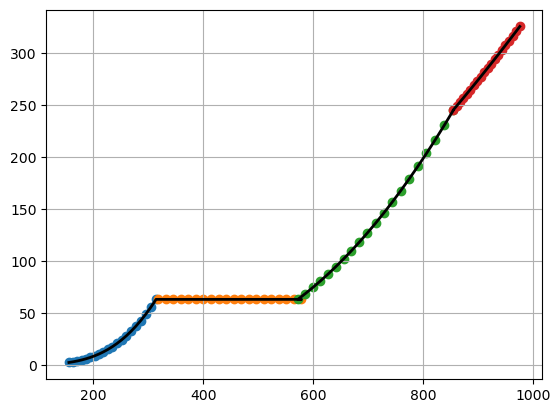

In [70]:
n1_b = np.linspace(n_b[0], n_b[1], 20)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = e_from_n(n1_b, K_b[0], Gam_b[0], m0[0])

n2_b = np.linspace(n_b[1], n_b[2], 20)
P2_b = P_from_nb(n2_b, K_b[1], Gam_b[1])
mu2_b = mu_from_nb(n2_b, K_b[1], Gam_b[1], m0[1])
e2_b = e_from_n(n2_b, K_b[1], Gam_b[1], m0[1])

n3_b = np.linspace(n_b[2], n_b[3], 20)
P3_b = P_from_nb(n3_b, K_b[2], Gam_b[2])
mu3_b = mu_from_nb(n3_b, K_b[2], Gam_b[2], m0[2])
e3_b = e_from_n(n3_b, K_b[2], Gam_b[2], m0[2])

n4_b = np.linspace(n_b[3], n_b[4], 20)
P4_b = P_from_nb(n4_b, K_b[3], Gam_b[3])
mu4_b = mu_from_nb(n4_b, K_b[3], Gam_b[3], m0[3])
e4_b = e_from_n(n4_b, K_b[3], Gam_b[3], m0[3])

 

plt.scatter(e1_b, P1_b);
plt.scatter(e2_b, P2_b);
plt.scatter(e3_b, P3_b);
plt.scatter(e4_b, P4_b);
plt.grid();

P_arr = np.concatenate((P1_b, P2_b, P3_b, P4_b))
n_arr = np.concatenate((e1_b, e2_b, e3_b, e4_b))
plt.plot(n_arr, P_arr, linewidth = 2, color = "black");

ValueError: x, y, and format string must not be None

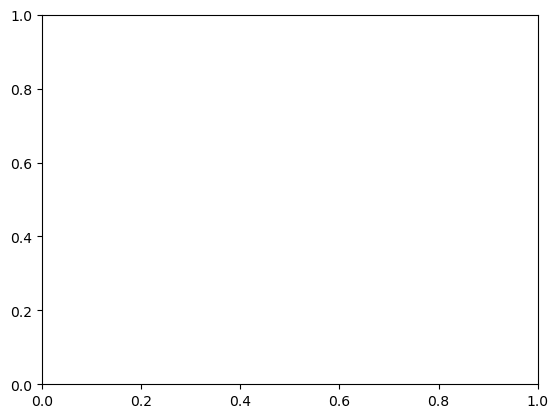

In [51]:

mu1_b = mu_from_nb(n_arr, K_b[0], Gam_b[0], m0[0])
mu3_b = mu_from_nb(n_arr, K_b[2], Gam_b[2], 991.75)
#print(min(mu1_b), min(mu3_b))
#print(max(mu1_b), max(mu3_b))



P_1_all = P_from_nb(n_arr, K_b[0], Gam_b[0])
P_3_all = P_from_nb(n_arr, K_b[2], Gam_b[2])

plt.plot(mu1_b, P_1_all, label = "hadronic")
plt.plot(mu3_b, P_3_all, label = "quark")

plt.xlabel("Chemical potential ")
plt.ylabel("Pressure ")
plt.legend()
plt.xlim([1000,1400])
plt.ylim([0,150])
plt.grid()
plt.show();

In [16]:
mu1_b = mu_from_nb(n_arr, K_b[0], Gam_b[0], m0[0])
mu4_b = mu_from_nb(n_arr, K_b[3], Gam_b[3], 991.75)
print(min(mu1_b), min(mu3_b))
print(max(mu1_b), max(mu3_b))



P_1_all = P_from_nb(n_arr, K_b[0], Gam_b[0])
P_4_all = P_from_nb(n_arr, K_b[3], Gam_b[3])

plt.plot(mu1_b, P_1_all, label = "hadronic")
plt.plot(mu4_b, P_4_all, label = "quark")

plt.xlabel("Chemical potential ")
plt.ylabel("Pressure ")
plt.legend()
plt.xlim([1000,1400])
plt.ylim([0,150])
plt.grid()
plt.show();

TypeError: 'NoneType' object is not iterable

In [ ]:
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu4_b)
y2 = np.array(P_4_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1050, 1385, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)


y_diff = np.abs(P_h_int_func(mu_new) - P_q_int_func(mu_new))
print("The index is :",np.argmin(y_diff), "the mu value is: ", mu_new[np.argmin(y_diff)])
x_intersect = mu_new[np.argmin(y_diff)]
y_intersect = P_h_int_func(x_intersect)
#%%
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([70,100])
plt.xlim([1220,1250])
plt.grid()
plt.show();


print(x_intersect, y_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)


In [ ]:
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu3_b)
y2 = np.array(P_3_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1050, 1385, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)


y_diff = np.abs(P_h_int_func(mu_new) - P_q_int_func(mu_new))
print("The index is :",np.argmin(y_diff), "the mu value is: ", mu_new[np.argmin(y_diff)])
x_intersect = mu_new[np.argmin(y_diff)]
y_intersect = P_h_int_func(x_intersect)
#%%
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([0,60])
plt.xlim([1050,1150])
plt.grid()
plt.show();


print(x_intersect, y_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)


In [ ]:
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re



mu_c_h = mu_new[np.argmin(y_diff) - 10]
mu_c_q = mu_new[np.argmin(y_diff) + 10]
P_h = P_h_int_func(mu_c_h)
P_q = P_q_int_func(mu_c_q)

print(mu_c_h, mu_c_q)
plt.scatter(mu_c_h, P_h)
plt.scatter(mu_c_q, P_q)
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([10,60])
plt.xlim([1070,1120])